# Chapter 07 — 그래프로 데이터의 이야기를 보여주기

- 이름: 송누리
- GitHub ID: HauserNR
- 작성일·미래 날짜 판정 기준일: 2026-10-28 (한국 날짜)
- 최종 Notebook URL: [chapter07/chapter07.ipynb](https://github.com/HauserNR/llm-data-analysis-study/blob/main/chapter07/chapter07.ipynb)

**질문 → 집계표 → 수치 검증 → 그래프 → 관찰·판단·한계** 순서로 읽는다. 공식 skeleton의 카테고리·월별·가격 분포·산점도·익명 고객·주문 상태 흐름을 따라 6개 질문을 분석했다. 대표 그래프는 1~3이고, 그래프 4~6은 관계·고객·상태를 확인하는 추가 분석이다.

입력은 Chapter 05에서 만든 `data/processed/*_clean.csv` 4개다. Chapter 05 사본과 바이트·해시를 대조한다. **여기서 금액은 전처리 후 남은 completed 주문 상세의 `quantity × unit_price` 합계다.** 할인·배송비·수수료·환불 이력·원가가 없어 회계상 순매출이나 이익으로 부르지 않는다.

코드·그래프 후보·해석 초안 작성에 Codex를 사용했다. 예시 수치를 답으로 옮기지 않고 아래 실행 결과와 실제 matplotlib 객체를 검증 기준으로 삼았다.

공식 자료: [skeleton Notebook](https://github.com/GilbertMoon/llm-data-analysis-course/blob/main/notebooks/ch07_visualization.ipynb), [실습 가이드](https://blog.naver.com/dev-dog/224414845375), [단계별 실습](https://github.com/GilbertMoon/llm-data-analysis-course/blob/main/practice/chapter07/chapter07.md), [답안 템플릿](https://github.com/GilbertMoon/llm-data-analysis-course/blob/main/practice/chapter07/templates/chapter07_assignment.md). 공식 코드·템플릿 사본은 `references/`에 보관했다.

## 0. 실행 방법과 제출 구조

커널을 재시작한 뒤 위에서 아래로 실행한다. 저장소 루트 또는 `chapter07/`에서 실행할 수 있다. 네트워크나 API 키가 필요하지 않으며 pandas·numpy·matplotlib·IPython과 한글 폰트를 사용한다. 이 저장소의 `.venv`를 커널로 선택하면 된다.

```text
chapter07/
├─ chapter07.ipynb        # 코드·실행 결과·집계표·그림·해석
├─ images/               # 그래프 PNG 6개
├─ reports/              # 집계 CSV·검증표·실행 요약
├─ src/visualization.py  # 입력·집계·그리기·객체 검증 공통 함수
├─ scripts/run_visualization.py
└─ references/           # 공식 skeleton·템플릿·모듈 사본
```

공식 모듈은 이 데이터의 주문/상품 FK 미연결을 발견하면 중단한다. 먼저 문제를 기록하고, **주문 상태 불명은 completed에서 제외, 상품 미연결은 별도 범주로 보존**하는 기준을 추가했다. 공통 함수를 `chapter07/src/`에 두어 이전 장의 `src`와 분리했다. 원본/processed CSV를 덮어쓰지 않는다.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import platform
import hashlib
import importlib.util
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = next(p for p in [CURRENT_DIR, *CURRENT_DIR.parents]
                    if (p / "chapter05/data/processed/orders_clean.csv").exists())
CHAPTER_DIR = PROJECT_ROOT / "chapter07"
PROCESSED_DIR = PROJECT_ROOT / "data/processed"
IMAGE_DIR = CHAPTER_DIR / "images"
REPORT_DIR = CHAPTER_DIR / "reports"
IMAGE_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
# 다른 장에서 src를 import했더라도 정확히 이 파일을 불러온다.
spec = importlib.util.spec_from_file_location("chapter07_visualization", CHAPTER_DIR / "src/visualization.py")
viz = importlib.util.module_from_spec(spec)
spec.loader.exec_module(viz)
PLOTTERS, FILENAMES = viz.PLOTTERS, viz.FILENAMES
selected_font = viz.setup_korean_font()
pd.set_option("display.max_rows", 45)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Python:", platform.python_version())
print("pandas / numpy / matplotlib:", pd.__version__, np.__version__, matplotlib.__version__)
print("프로젝트 가상환경:", Path(sys.prefix).name == ".venv")
print("한글 폰트:", selected_font)
print("입력: data/processed/ | 출력: chapter07/images/, chapter07/reports/")

Python: 3.12.0
pandas / numpy / matplotlib: 3.0.5 2.5.3 3.11.1
프로젝트 가상환경: True
한글 폰트: Apple SD Gothic Neo
입력: data/processed/ | 출력: chapter07/images/, chapter07/reports/


## 1. 시각화 질문과 그래프 선택

금액을 비교하기 전에 질문·대상·범위·지표를 고정했다. Q1~3을 대표로 선택한 이유는 **범주 비교, 시간 변화, 분포**라는 서로 다른 분석 목적을 보여 주기 때문이다.

| 질문 | 대상·분석 범위 | 지표 | 선택한 그래프 | 선택 이유 |
|---|---|---|---|---|
| Q1. 어느 카테고리의 완료 상세 금액이 큰가? | completed 전체 상세, 날짜 제한 없음, 상품 미연결 별도 | 카테고리별 금액·수량·비중 | 세로 막대 | 범주별 크기·순위를 같은 0 기준에서 비교 |
| Q2. 월별 완료 금액과 주문 수는 어떻게 움직이는가? | completed 중 유효 날짜·기준일 이하 | 월별 금액·주문 수·주문당 금액 | 두 패널 선그래프 | 시간 간격을 유지하고 금액·건수를 서로 다른 축 패널에서 비교 |
| Q3. 상품 마스터 가격은 어떻게 분포하는가? | 전체 상품 96개, 주문 상태 무관 | 가격 구간별 상품 수·중앙값·극단값 | 히스토그램 | 수치형 가격의 구간별 빈도 확인, bins 10/20/30 비교 |
| Q4. 상품 가격과 완료 판매 수량은 어떤 관계인가? | 상품이 연결되는 completed 상세를 상품별 집계, 날짜 제한 없음 | 마스터 가격·완료 판매 수량 | 산점도 | 한 점을 상품 하나로 하여 두 수치의 관계 탐색 |
| Q5. 완료 금액 상위 고객의 금액·횟수는 어떠한가? | 고객 마스터에 연결된 구매자, 날짜 제한 없음 | 고객별 금액·완료 주문 수 | 익명 가로 막대 | 순위·긴 라벨을 읽기 쉽고, 주문 횟수를 함께 표기 |
| Q6. 전체 주문은 어떤 상태로 구성되는가? | 전체 orders 헤더, 날짜 제한 없음 | 상태별 주문 수·비율 | 막대 | 서로 배타적인 상태별 건수 비교 |

개인 판단: Q2에서 금액·건수를 이중 y축에 겹치면 함께 움직이는 정도를 과장할 수 있어 위아래 패널로 나눴다. Q3·4에서 극단값을 조용히 삭제하지 않고 전체 그래프와 명시적인 보조 비교를 함께 제시한다.

## 2. 그래프 전 입력·병합·completed 범위 검증

필수 컬럼, PK 결측·중복, 양수·유한 숫자, `line_total` 산식, `many_to_one` 병합, 입력 보존을 확인한다. **데이터 품질 문제의 발견과 집계 검증 통과는 다르다.** FK 문제는 아래 품질 표에 남기고, 정의한 범위 내 합계가 보존되는지를 따로 검증한다. 고객 이름·주소·나이 등은 읽지 않으며 공개 표에도 원본 고객 ID를 넣지 않는다.

In [2]:
viz_data = viz.prepare_visualization_data(PROJECT_ROOT)
products = viz_data["products"]
orders = viz_data["orders"]
completed = viz_data["completed"]
category_sales = viz_data["category"]
monthly_sales = viz_data["monthly"]
product_sales = viz_data["scatter"]
customer_sales = viz_data["customers"]
order_status = viz_data["status"]
chart_checks = []
input_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                for p in PROCESSED_DIR.glob("*_clean.csv")}
display(viz_data["input_manifest"])
print("completed 상세:", len(completed), "행 / 주문", completed.order_id.nunique(), "건")
print("completed source total:", f"{completed.line_total.sum():,.0f}원")
display(viz_data["scope"])
display(viz_data["quality"])

,file,rows,sha256,same_as_ch05
0,customers_clean.csv,150,f14a59af4a8a900c0b9f72c7fab3367df2ba1e1419f24f...,True
1,products_clean.csv,96,b6a1f8263f815c9990f01049f87c17f9d45ed6b45d4583...,True
2,orders_clean.csv,300,b7264a74270919ae0b9c1d7bc999f7c0f472d97dfdf445...,True
3,order_items_clean.csv,752,82389ef808e4f9db56ad76e52fe511b0face3f016cb817...,True


completed 상세: 446 행 / 주문 179 건
completed source total: 141,340,000원


,scope,count_in_scope,count_unit,amount_krw
0,전체 주문 헤더,300,주문,NaN
1,completed 주문 헤더,180,주문,NaN
2,상세가 남은 completed 주문,179,주문,"141,340,000.00"
3,카테고리 전체(미연결 포함),446,상세 행,"141,340,000.00"
4,월별(유효 날짜·기준일 이전),437,상세 행,"138,528,000.00"
5,산점도(상품 연결 completed 상세),430,상세 행,"137,325,000.00"
6,고객 순위(고객 연결 completed 상세),445,상세 행,"140,964,000.00"


,issue_and_policy,detail_rows,amount_krw
0,주문 미연결 상세: 상태 불명으로 completed 범위 밖,2,"922,000.00"
1,completed 상품 미연결: 카테고리 별도/산점도 제외,16,"4,015,000.00"
2,completed 날짜 결측: 월별만 제외,6,"1,903,000.00"
3,completed 기준일 이후: 월별만 제외,3,"909,000.00"
4,completed 고객 미연결: 고객 순위 제외,1,"376,000.00"


### 발견한 문제와 분석 범위 판단

- 주문 미연결 상세 **2행·922,000원**은 주문 상태를 알 수 없어 completed로 추정하지 않았다.
- completed **446상세·179주문·141,340,000원**을 카테고리 분석의 기준으로 삼았다. completed 주문 헤더는 **180건**이지만 1건은 processed 상세가 남아 있지 않다. 빈 상세를 0원 주문이라고 단정하지 않았다.
- completed 상품 미연결 **16상세·4,015,000원(2.84%)**은 Q1의 `상품 미연결`로 남긴다. 가격을 알 수 없으므로 Q4에서만 제외한다.
- 날짜 결측 **6상세·1,903,000원**, 기준일 이후 **3상세·909,000원**은 Q2에서만 제외한다. 따라서 월별 합은 **138,528,000원**이며 전체 completed 금액과 다른 이유가 설명된다.
- 고객 미연결 **1상세·376,000원**은 Q5 순위에서 제외하고 총합 대조에서는 별도로 더한다. 고객 연결 금액은 **140,964,000원**이다.

품질 문제 금액은 서로 겹칠 수 있으므로 합쳐서 손실액으로 해석하지 않는다. Q1·4·5는 Chapter 06과 비교하기 위해 날짜 제한 없는 completed 스냅샷을 사용한다. 따라서 이들 결과는 기준일까지 발생한 거래만의 확정 실적이 아니다. Q2의 시계열만 미래 날짜를 제외한다.

In [3]:
# 금액 합계는 그룹 집계와 독립적인 isin 필터로도 대조한다.
source_total = completed.line_total.sum()
source_items = pd.read_csv(PROCESSED_DIR / "order_items_clean.csv")
completed_ids = orders.loc[orders.order_status.eq("completed"), "order_id"]
independent_total = source_items.loc[source_items.order_id.isin(completed_ids), "line_total"].sum()
assert np.isclose(source_total, independent_total, rtol=0, atol=1e-6)
display(viz_data["validation"])
assert viz_data["validation"].passed.all()
print("범위를 명시한 집계 검증 통과. FK·날짜 문제가 해결되었다는 뜻은 아님.")

,check,actual,expected,passed
0,상세별 line_total = quantity × unit_price,"252,140,000.00","252,140,000.00",True
1,병합 후 상세 행 수 보존,752.00,752.00,True
2,상품 병합 후 completed 상세 보존,446.00,446.00,True
3,completed 독립 isin 필터 총합,"141,340,000.00","141,340,000.00",True
4,카테고리 총합(상품 미연결 포함),"141,340,000.00","141,340,000.00",True
5,월별 + 날짜 결측 + 미래 = completed,"141,340,000.00","141,340,000.00",True
6,상품별 + 상품 미연결 = completed,"141,340,000.00","141,340,000.00",True
7,익명 고객별 + 고객 미연결 = completed,"141,340,000.00","141,340,000.00",True
8,상태별 주문 수 총합,300.00,300.00,True
9,Chapter 06 completed 총합 대조,"141,340,000.00","141,340,000.00",True


범위를 명시한 집계 검증 통과. FK·날짜 문제가 해결되었다는 뜻은 아님.


### 검증 결과 기록

카테고리 합계는 141,340,000원으로 completed source total과 같았다. 월별 금액에 날짜 결측·미래 금액을 더해도 같은 합계였다. 산점도의 상품 연결 금액과 상품 미연결 금액, 익명 고객 금액과 고객 미연결 금액도 각각 같은 총액으로 연결된다.

이 기준에서는 연결 누락을 숨기거나 거래를 중복시키지 않고 시각화를 진행할 수 있다고 판단했다. 다만 입력에서 이미 제외된 비양수·변환 실패 상세는 복구하지 않았으므로 원본 전체 거래 금액이라고 해석하지 않는다.

## 3. 대표 그래프 1 — 카테고리별 완료 상세 금액 (막대)

**질문:** 카테고리별 완료 금액의 크기와 비중은 어떻게 다른가? 범주를 비교하므로 막대그래프를 선택했다. 날짜 제한 없는 completed 상세만 사용한다. 금액 내림차순으로 정렬하고 y축은 0에서 시작한다. 상품 미연결은 회색·빗금·문자 라벨로 구분한다.

In [4]:
# 그래프 전 원본 집계값 확인
category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct", "weighted_unit_price"]]

,category,total_quantity,completed_amount,amount_ratio_pct,weighted_unit_price
0,패션,290.00,"32,940,000.00",23.31,"113,586.21"
1,식품,226.00,"25,035,000.00",17.71,"110,774.34"
2,전자기기,181.00,"21,590,000.00",15.28,"119,281.77"
3,뷰티,180.00,"17,751,000.00",12.56,"98,616.67"
4,도서,174.00,"17,663,000.00",12.50,"101,511.49"
5,스포츠,165.00,"13,237,000.00",9.37,"80,224.24"
6,생활용품,125.00,"9,109,000.00",6.44,"72,872.00"
7,상품 미연결,34.00,"4,015,000.00",2.84,"118,088.24"


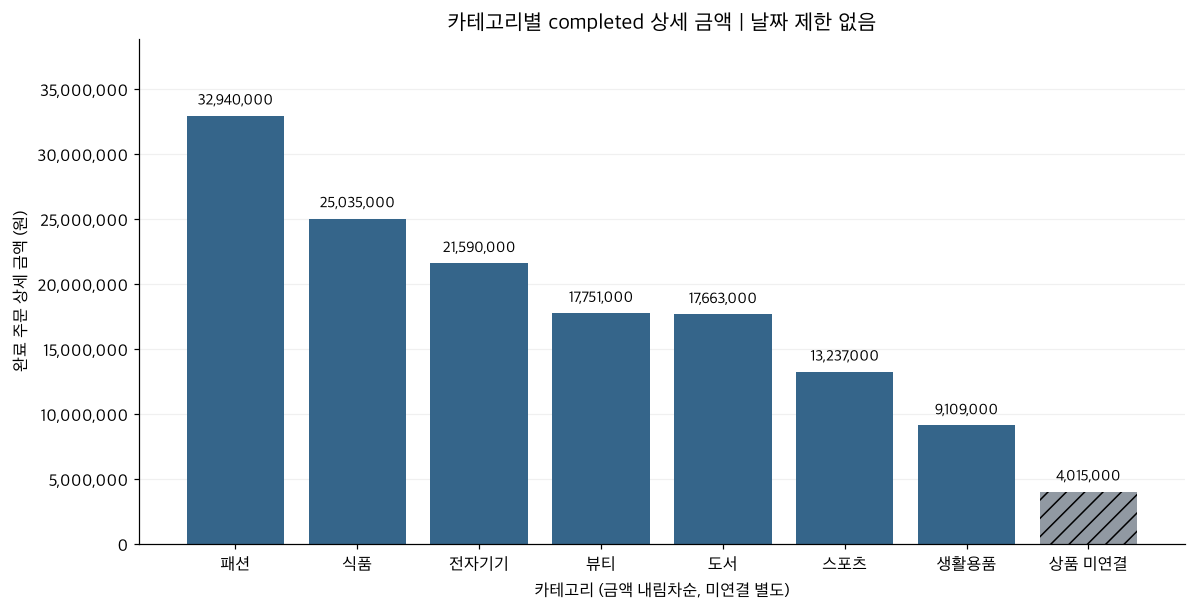

저장: images/graph01_category.png
실제 그래프 객체와 원본 집계표 검증: True


In [5]:
fig, checks = PLOTTERS["category"](viz_data)
chart_checks.extend(checks)
fig.savefig(IMAGE_DIR / FILENAMES["category"], bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)
print("저장:", "images/" + FILENAMES["category"])
print("실제 그래프 객체와 원본 집계표 검증:", all(row["passed"] for row in checks))

### 원본 집계값

패션 **32,940,000원·290개·23.31%**, 식품 **25,035,000원·226개·17.71%**, 전자기기 **21,590,000원·181개·15.28%**다. 전체 합계는 **141,340,000원**이며 상품 미연결 **4,015,000원**을 포함한다. 막대 8개의 실제 높이와 집계표 전부를 비교했다.

### 결과 관찰

패션이 금액·수량 모두 가장 크고, 알려진 카테고리 중 생활용품은 **9,109,000원·125개**로 금액이 가장 작다. 패션과 생활용품의 차이는 **23,831,000원**이다. 상품 미연결은 실제 카테고리명이 아니다.

### 나의 해석과 판단

패션은 이 표본의 완료 금액에서 가장 큰 비중을 차지하므로 후속 상세 분석의 우선 후보로 판단했다. 금액 1위를 바로 선호도 1위로 바꾸지 않았다. 거래금액/수량으로 계산한 가중 거래단가는 패션 약 **113,586원**, 전자기기 약 **119,282원**이므로 단가 순위와 금액 순위도 같지 않다.

### 업무·분석적 의미

상품별 기여도·판매 수량·고수량 주문 집중도를 함께 살펴 재고·구색 검토의 대상을 좁힐 수 있다. 금액이 낮은 범주를 곧바로 축소하기보다 상품 수와 판매 기간을 확인해야 한다.

### 한계와 추가 확인 사항

금액은 이익·만족도·구매 전환율을 설명하지 않는다. 상품 미연결 복구 시 분류와 순위가 달라질 수 있다. 날짜 결측·미래 거래가 포함된 전체 completed 스냅샷이며 실제 완료 시점은 알 수 없다. **다음 질문:** 기준일 이하·날짜 유효 범위로 통일해도 순위가 유지되는가? 패션 금액이 몇 상품·주문에 집중되는가?

## 4. 대표 그래프 2 — 월별 완료 금액과 주문 수 (선)

**질문:** 월별 완료 금액의 변화에 주문 수·주문당 금액이 어떻게 함께 나타나는가? 시간 순서가 중요하므로 선그래프를 선택했다. 유효 주문일·2026-10-28 이하인 completed 상세로 제한했다.

중간 월은 달력으로 재색인한다. 해당 월 전체 orders 행이 없으면 **NaN(수집 여부 불명)**으로 남겨 선을 끊는다. orders는 있지만 completed 상세가 없으면 **파일 내 관측 상세 금액 0**으로 구분하며 실제 업무의 무거래라고 단정하지 않는다. 2026년 9~10월은 관측 종료 뒤이므로 0으로 연장하지 않는다.

In [6]:
# 원본 월별 집계값·관측 범위 확인
print("유효·기준일 이하 주문일 범위:")
print(orders.loc[orders.order_date.le(viz.AS_OF), "order_date"].agg(["min", "max"]))
display(monthly_sales[["month", "completed_amount", "completed_order_count",
                       "average_completed_order_amount", "all_order_rows", "coverage"]])
assert monthly_sales.month.is_monotonic_increasing
assert np.isclose(monthly_sales.completed_amount.sum(), 138_528_000)
# 해당 데이터에서 실제로 빠진 중간 월이 있는지 확인한다.
print("전체 주문 행이 없는 중간 월:", monthly_sales.loc[monthly_sales.all_order_rows.eq(0), "month"].astype(str).tolist())
print("날짜 결측 1,903,000 + 미래 909,000 + 월별", f"{monthly_sales.completed_amount.sum():,.0f}", "= 141,340,000원")

유효·기준일 이하 주문일 범위:
min   2025-07-01
max   2026-08-30
Name: order_date, dtype: datetime64[us]


,month,completed_amount,completed_order_count,average_completed_order_amount,all_order_rows,coverage
0,2025-07,"9,561,000.00",11,"869,181.82",19,완료 상세 관측
1,2025-08,"9,362,000.00",17,"550,705.88",26,완료 상세 관측
2,2025-09,"5,299,000.00",4,"1,324,750.00",12,완료 상세 관측
3,2025-10,"12,629,000.00",17,"742,882.35",22,완료 상세 관측
4,2025-11,"9,583,000.00",16,"598,937.50",23,완료 상세 관측
5,2025-12,"8,581,000.00",12,"715,083.33",23,완료 상세 관측
6,2026-01,"8,135,000.00",9,"903,888.89",26,완료 상세 관측
7,2026-02,"7,689,000.00",12,"640,750.00",19,완료 상세 관측
8,2026-03,"7,247,000.00",13,"557,461.54",22,완료 상세 관측
9,2026-04,"11,459,000.00",14,"818,500.00",26,완료 상세 관측


전체 주문 행이 없는 중간 월: []
날짜 결측 1,903,000 + 미래 909,000 + 월별 138,528,000 = 141,340,000원


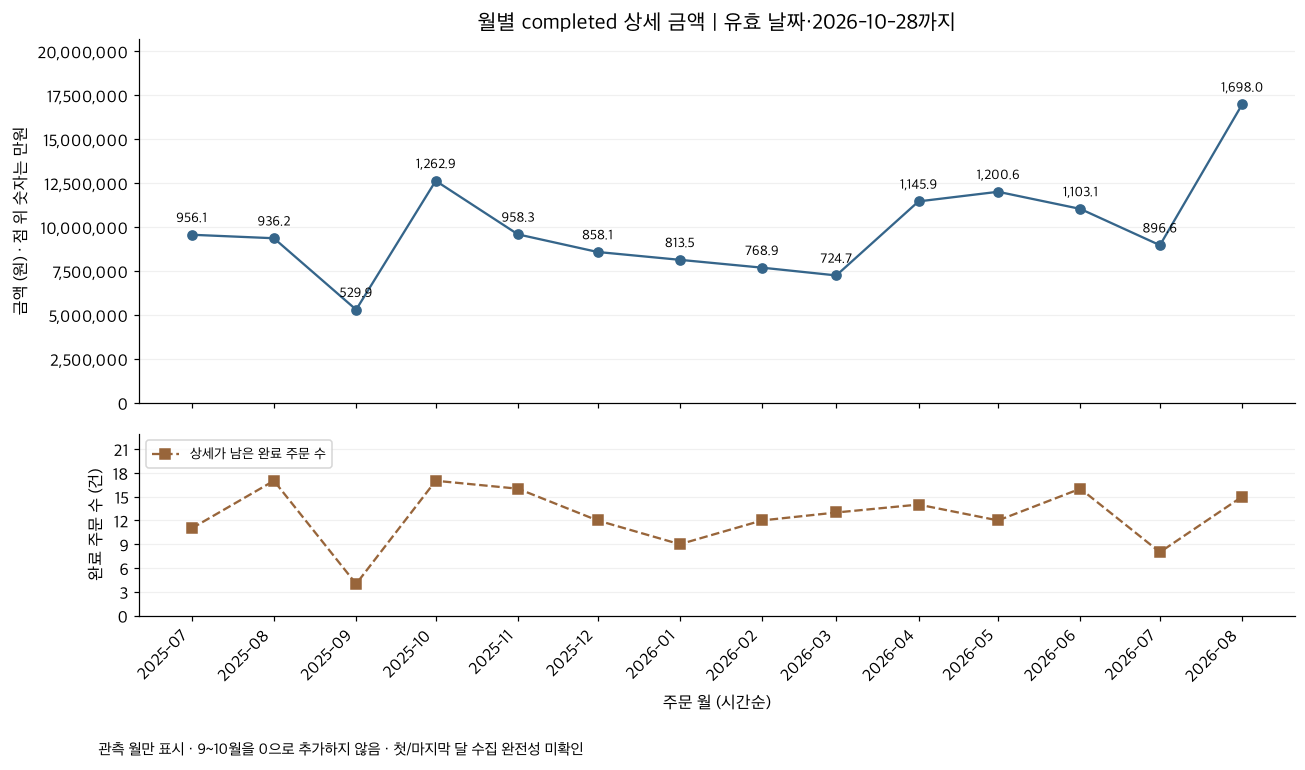

저장: images/graph02_monthly.png
실제 그래프 객체와 원본 집계표 검증: True


In [7]:
fig, checks = PLOTTERS["monthly"](viz_data)
chart_checks.extend(checks)
fig.savefig(IMAGE_DIR / FILENAMES["monthly"], bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)
print("저장:", "images/" + FILENAMES["monthly"])
print("실제 그래프 객체와 원본 집계표 검증:", all(row["passed"] for row in checks))

### 원본 집계값

2025-07~2026-08의 **14개월·138,528,000원**이다. 2026년 7월은 **8,966,000원·8건·주문당 1,120,750원**, 8월은 **16,980,000원·15건·주문당 1,132,000원**이다. 선의 금액·건수·실제 날짜 좌표를 원본 집계와 전부 대조했다.

### 결과 관찰

8월은 표시된 월 중 가장 높다. 7월 대비 금액은 **8,014,000원(약 89.38%)**, 주문 수는 **7건(87.5%)** 증가했다. 주문당 금액 증가는 **11,250원(약 1.00%)**이다. 전 기간에 걸쳐 계속 증가하는 형태는 아니다.

### 나의 해석과 판단

두 달의 금액 차이는 주문당 금액보다 관측된 주문 수 변화와 함께 더 크게 나타났다. 이는 금액=주문 수×주문당 금액이라는 집계상의 설명이다. 주문 증가를 일으킨 광고·계절성·프로모션 원인을 증명한 것은 아니다.

### 업무·분석적 의미

8월 증가를 단가 개선 성과라고 보고하기 전에 신규/반복 구매 주문 수, 카테고리 구성, 고액 주문 집중도를 확인할 필요가 있다. 금액만 보는 것보다 주문 수·주문당 금액을 함께 보면 후속 질문을 구체화할 수 있다.

### 한계와 추가 확인 사항

orders의 유효·기준일 이하 날짜는 **2025-07-01~2026-08-30**이다. 첫 달이 1일에 시작해도 수집 완전성이 증명되지는 않으며, 마지막 달은 31일 포함 여부를 모른다. 9~10월 데이터 부재는 0원이 아니다. 날짜 결측 1,903,000원을 어느 달에도 배분하지 않았고 미래 909,000원도 제외했다. 상세 없는 완료 주문을 포함한 모든 실제 완료 주문 수가 아니다. **다음 질문:** 일자별 수집 누락을 확인하고 같은 기간·품목 범위에서 월별 차이를 비교해도 패턴이 남는가?

## 5. 대표 그래프 3 — 상품 마스터 가격 분포 (히스토그램)

**질문:** 상품 가격의 분포와 극단값 후보가 어떠한가? 가격 구간별 상품 수를 보려는 질문이므로 히스토그램을 선택했다. 전체 상품 마스터는 주문 속성이 아니므로 completed 필터를 적용하지 않는다.

위 패널은 전체 96개, 아래는 **100만원 이하 95개만을 따로 비교한 보조 분석**이다. 아래 패널 때문에 원본 극단값을 삭제하거나 집계 총액을 다시 계산하지 않는다. 각 범위에서 bins=10·20·30을 비교한다. 상하 패널의 y축 범위도 다르므로 빈도 높이를 직접 비교하지 않는다.

In [8]:
# 그래프 전 기술통계·구간별 실제 빈도 확인
price_values = products.price.to_numpy()
display(products.price.describe().rename("price_krw").to_frame())
histogram_rows = []
for label, values in [("전체 96개", price_values), ("보조: 100만원 이하 95개", price_values[price_values <= 1_000_000])]:
    for bins in [10, 20, 30]:
        counts, edges = np.histogram(values, bins=bins)
        assert counts.sum() == len(values)
        for j, count in enumerate(counts):
            histogram_rows.append({"scope": label, "bins": bins, "left_krw": edges[j],
                                   "right_krw": edges[j+1], "count": int(count),
                                   "right_inclusive": j == len(counts)-1})
histogram_table = pd.DataFrame(histogram_rows)
print("구간은 [왼쪽, 오른쪽), 마지막 구간만 오른쪽 포함")
display(histogram_table.query("bins == 20"))
histogram_table.to_csv(REPORT_DIR / "histogram_bins.csv", index=False)

,price_krw
count,96.00
mean,"204,895.82"
std,"1,011,847.94"
min,"5,000.00"
25%,"52,750.00"
50%,"94,500.00"
75%,"153,250.00"
max,"9,999,999.00"


구간은 [왼쪽, 오른쪽), 마지막 구간만 오른쪽 포함


,scope,bins,left_krw,right_krw,count,right_inclusive
10,전체 96개,20,"5,000.00","504,749.95",95,False
11,전체 96개,20,"504,749.95","1,004,499.90",0,False
12,전체 96개,20,"1,004,499.90","1,504,249.85",0,False
13,전체 96개,20,"1,504,249.85","2,003,999.80",0,False
14,전체 96개,20,"2,003,999.80","2,503,749.75",0,False
15,전체 96개,20,"2,503,749.75","3,003,499.70",0,False
16,전체 96개,20,"3,003,499.70","3,503,249.65",0,False
17,전체 96개,20,"3,503,249.65","4,002,999.60",0,False
18,전체 96개,20,"4,002,999.60","4,502,749.55",0,False
19,전체 96개,20,"4,502,749.55","5,002,499.50",0,False


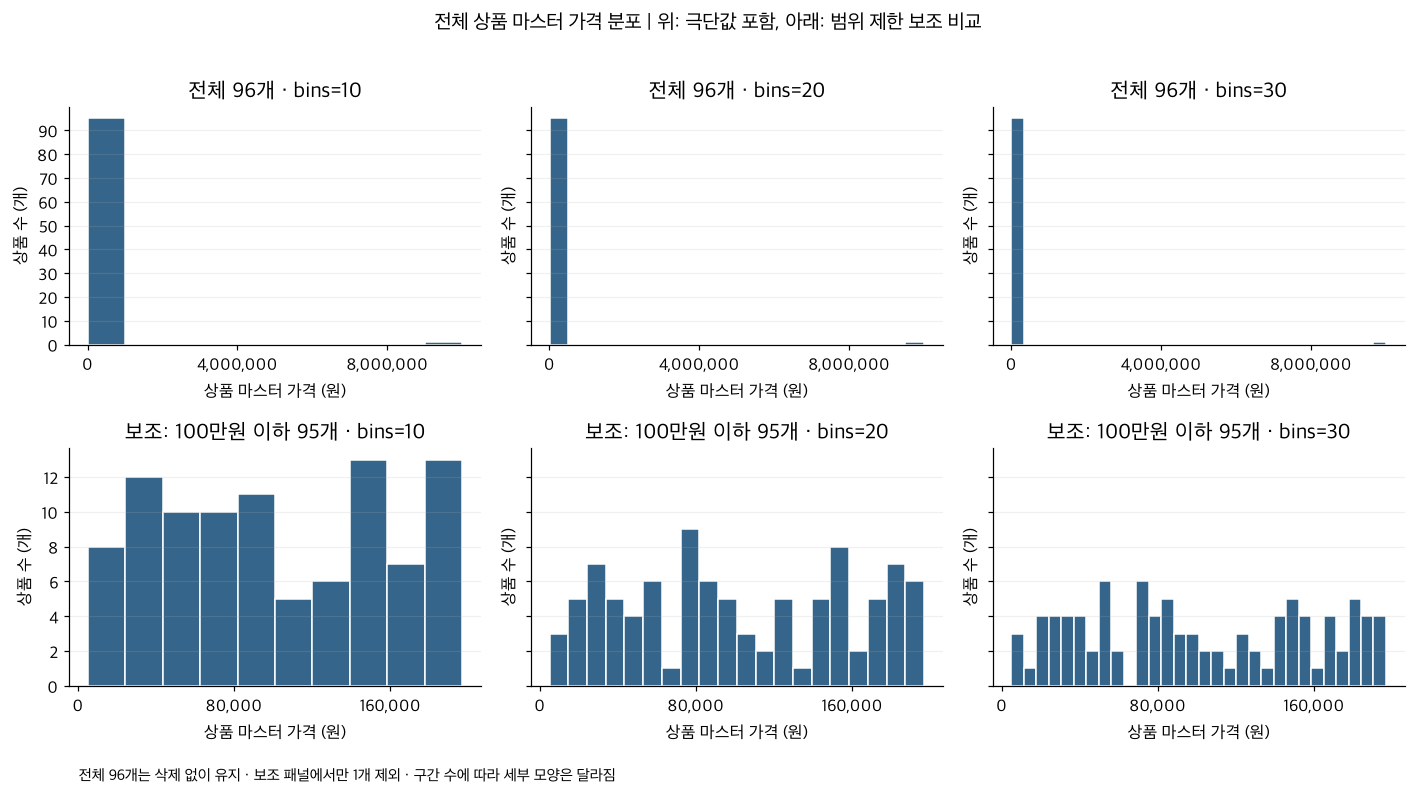

저장: images/graph03_price.png
실제 그래프 객체와 원본 집계표 검증: True


In [9]:
fig, checks = PLOTTERS["price"](viz_data)
chart_checks.extend(checks)
fig.savefig(IMAGE_DIR / FILENAMES["price"], bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)
print("저장:", "images/" + FILENAMES["price"])
print("실제 그래프 객체와 원본 집계표 검증:", all(row["passed"] for row in checks))

### 원본 집계값

상품 **96개**, 최솟값 **5,000원**, 중앙값 **94,500원**, 평균 약 **204,896원**, 최댓값 **9,999,999원**이다. 이 최대 가격을 제외한 나머지 **95개**는 **5,000~197,000원**, 중앙값 **93,000원**, 평균 약 **101,789원**이다. 6개 패널 각각의 구간 경계·구간별 빈도·실제 막대 높이를 `numpy.histogram` 결과와 대조했다.

### 결과 관찰

전체 상품의 **95/96개(98.96%)**가 197,000원 이하이고 한 상품만 훨씬 큰 가격을 가진다. 전체 범위에서는 bins를 바꿔도 95개가 첫 구간에 몰린다. 보조 범위에서는 bin 수에 따라 여러 봉우리의 모양·위치가 달라져 하나의 인기 가격대를 확정하기 어렵다.

### 나의 해석과 판단

평균 하나만으로 대표 가격을 설명하면 극단값의 영향을 크게 받으므로 중앙값과 범위도 함께 제시하는 것이 적절하다고 판단했다. 9,999,999원은 원천 확인 우선 후보지만 그래프 모양만으로 오류라고 판정하거나 자동 삭제하지 않았다.

### 업무·분석적 의미

가격 데이터 검수의 우선순위를 정하고, 일반 상품군의 가격대를 살펴볼 수 있다. 가격대별 구색을 검토할 때는 판매량으로 가중하지 않은 상품 마스터 분포라는 점을 밝혀야 한다.

### 한계와 추가 확인 사항

상품 마스터 가격은 실제 거래단가나 고객 지불 의향이 아니다. 보조 패널은 의도적으로 범위를 제한했으므로 전체 가격 분포로 읽으면 안 된다. bins와 작은 상품 수에 따라 봉우리가 달라지며, 고가 상품의 존재만으로 고가 전략이 성공했다고 말할 수 없다. **다음 질문:** 극단값이 실제 등록 가격인지 확인하고 카테고리별 마스터·거래단가 차이와 판매 여부를 살펴볼 것인가?

## 6. 추가 그래프 4 — 가격과 completed 판매 수량 (산점도)

**질문:** 상품 가격과 관측된 완료 판매 수량 사이에 어떤 패턴이 보이는가? 두 수치형 변수의 관계이므로 산점도를 선택했다. 상품 연결 completed 상세를 상품별로 합쳤다. 한 점은 상품 하나다. 왼쪽은 전체 선형 축, 오른쪽은 **같은 모든 점의 x축만 로그로 변환**한 보조 비교다. 로그 축은 0에서 시작할 수 없으므로 명시했다.

In [10]:
# 그래프 전 모든 점의 좌표와 상관 민감도 확인 (개인정보·원본 키 없음)
display(product_sales)
regular_products = product_sales.loc[product_sales.price.le(1_000_000)]
correlations = pd.DataFrame([
    {"scope": name, "products": len(frame),
     "pearson": frame.price.corr(frame.completed_quantity),
     "spearman": frame.price.corr(frame.completed_quantity, method="spearman")}
    for name, frame in [("전체 연결 상품", product_sales), ("100만원 이하 보조", regular_products)]
])
display(correlations)
correlations.to_csv(REPORT_DIR / "scatter_sensitivity.csv", index=False)

,price,completed_quantity,completed_amount
0,"61,000.00",13.00,"793,000.00"
1,"154,000.00",12.00,"1,848,000.00"
2,"48,000.00",7.00,"336,000.00"
3,"33,000.00",15.00,"495,000.00"
4,"73,000.00",15.00,"1,095,000.00"
...,...,...,...
90,"96,000.00",70.00,"6,720,000.00"
91,"187,000.00",26.00,"4,862,000.00"
92,"32,000.00",10.00,"320,000.00"
93,"9,999,999.00",8.00,"1,496,000.00"


,scope,products,pearson,spearman
0,전체 연결 상품,95,-0.07,-0.05
1,100만원 이하 보조,94,-0.01,-0.04


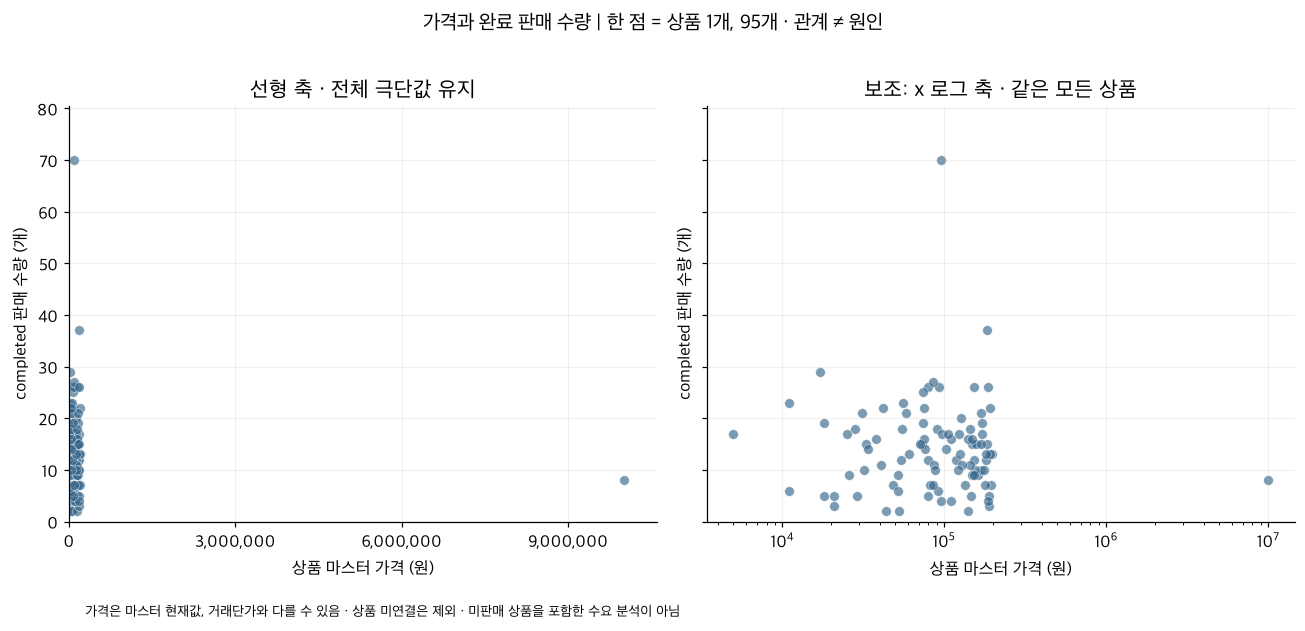

저장: images/graph04_scatter.png
실제 그래프 객체와 원본 집계표 검증: True


In [11]:
fig, checks = PLOTTERS["scatter"](viz_data)
chart_checks.extend(checks)
fig.savefig(IMAGE_DIR / FILENAMES["scatter"], bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)
print("저장:", "images/" + FILENAMES["scatter"])
print("실제 그래프 객체와 원본 집계표 검증:", all(row["passed"] for row in checks))

### 원본 집계값

상품 연결 **430상세·137,325,000원**을 **95개 판매 상품**으로 집계했다. 가격은 **5,000~9,999,999원**, 수량은 **2~70개**다. 상품 미연결 **16상세·4,015,000원**은 가격을 몰라 제외했다. 두 패널의 실제 점 좌표 전체가 원본 상품별 가격·수량과 일치했다.

### 결과 관찰

선형 축에서는 극단 가격 때문에 대부분의 점이 왼쪽에 겹친다. 로그 보조 축에서는 일반 가격대에서도 수량이 다양하게 나타난다. 전체 상품 Pearson은 약 **-0.070**, Spearman은 약 **-0.051**이며, 100만원 이하만 보면 각각 약 **-0.014**, **-0.037**이다.

### 나의 해석과 판단

현재 표본에서는 뚜렷한 단순 선형·단조 관계가 강하게 나타나지 않는다고 판단했다. 상관이 작다는 것이 가격의 영향이 없다는 증거는 아니다. 극단 가격 상품은 완료 수량 **8개·거래금액 1,496,000원**이어서 마스터 가격과 거래단가가 같다고 놓고 매출을 재계산해서도 안 된다.

### 업무·분석적 의미

가격 인상·인하의 효과를 판단하는 데 이 그림만 사용하지 않는다. 먼저 마스터 가격의 기준 시점과 거래단가 차이를 확인하고, 같은 카테고리·판매 기간·재고 조건 안에서 비교하는 분석으로 이어갈 수 있다.

### 한계와 추가 확인 사항

상품 마스터는 96개지만 완료 판매가 관측된 연결 상품 95개만 포함했다. 미판매 상품·판매 기간·노출·재고·광고·할인 정보가 빠졌고 카테고리별 혼합도 존재한다. 관계는 원인을 증명하지 않는다. **다음 질문:** 미판매 상품과 노출 기간까지 포함하고 실제 거래단가 기준으로 비교하면 어떤 패턴이 남는가?

## 7. 추가 그래프 5 — 완료 금액 상위 고객 (익명 가로 막대)

**질문:** 관측 금액 상위 고객의 구매 횟수와 금액은 어떠한가? 고객 마스터에 연결된 구매자만 금액 내림차순으로 정렬한다. 순위는 원본 고객 ID가 아니며 이름·개인 키를 공개하지 않는다. 긴 순위 라벨을 읽기 쉽도록 가로 막대를 선택하고 주문 횟수도 문자로 표시한다.

In [12]:
# 원본 집계값은 공개용 익명 순위로만 출력한다.
top_customers = customer_sales.head(10)
display(top_customers[["anonymous_rank", "completed_order_count", "completed_amount", "average_completed_order_amount"]])
print("고객 연결 구매자:", len(customer_sales), "명")
print("고객 연결 금액:", f"{customer_sales.completed_amount.sum():,.0f}원")
print("상위 10명 비중:", f"{top_customers.completed_amount.sum() / customer_sales.completed_amount.sum() * 100:.2f}%")
assert not any(c in customer_sales.columns for c in ["customer_id", "name", "email", "address"])

,anonymous_rank,completed_order_count,completed_amount,average_completed_order_amount
0,구매금액 순위 01,3,"6,702,000.00","2,234,000.00"
1,구매금액 순위 02,4,"5,204,000.00","1,301,000.00"
2,구매금액 순위 03,3,"4,311,000.00","1,437,000.00"
3,구매금액 순위 04,4,"4,001,000.00","1,000,250.00"
4,구매금액 순위 05,6,"3,977,000.00","662,833.33"
5,구매금액 순위 06,2,"3,966,000.00","1,983,000.00"
6,구매금액 순위 07,4,"3,808,000.00","952,000.00"
7,구매금액 순위 08,4,"3,656,000.00","914,000.00"
8,구매금액 순위 09,4,"3,201,000.00","800,250.00"
9,구매금액 순위 10,3,"3,109,000.00","1,036,333.33"


고객 연결 구매자: 98 명
고객 연결 금액: 140,964,000원
상위 10명 비중: 29.75%


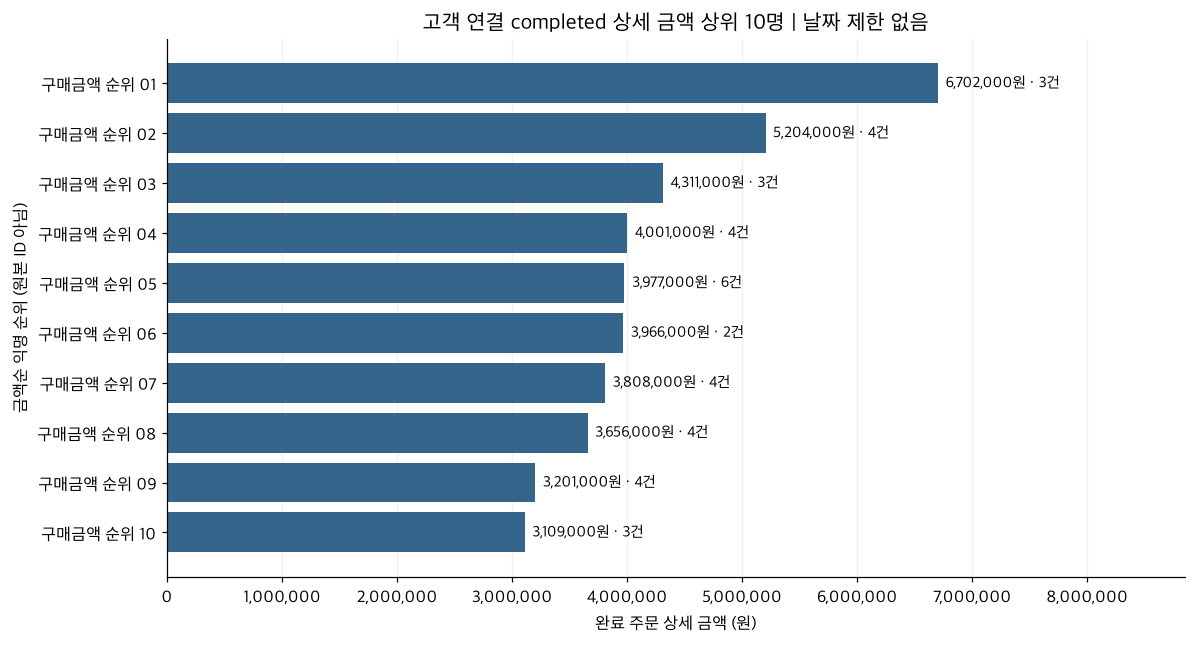

저장: images/graph05_customers.png
실제 그래프 객체와 원본 집계표 검증: True


In [13]:
fig, checks = PLOTTERS["customers"](viz_data)
chart_checks.extend(checks)
fig.savefig(IMAGE_DIR / FILENAMES["customers"], bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)
print("저장:", "images/" + FILENAMES["customers"])
print("실제 그래프 객체와 원본 집계표 검증:", all(row["passed"] for row in checks))

### 원본 집계값

고객 연결 구매자는 **98명·140,964,000원**이다. 1위는 **6,702,000원·3건**, 2위는 **5,204,000원·4건**이며, 상위 10명 합계는 **41,935,000원**, 고객 연결 금액의 **29.75%**다. 이 분모에 고객 미연결 376,000원은 포함하지 않았다. 모든 막대 너비와 순위 라벨을 집계표와 확인했다.

### 결과 관찰

금액 1위의 주문 수는 3건이지만 5위는 6건이다. 구매 금액과 구매 횟수의 순위가 같지 않다. 표시된 10명 이외에도 88명의 연결 구매자가 있다.

### 나의 해석과 판단

고액 고객의 패턴을 주문 횟수와 함께 보는 것이 단순 금액 순위보다 유용하다고 판단했다. 금액이 높다는 이유만으로 충성 고객이나 미래의 고가치 고객으로 분류하지 않았다.

### 업무·분석적 의미

후속 분석에서 고액 단발 구매와 반복 구매를 구분할 후보를 정할 수 있다. 마케팅 대상으로 바로 지정하기 전에 구매 기간·최근성·관측 누락을 확인해야 한다.

### 한계와 추가 확인 사항

Top 10은 전체 고객 분포를 대표하지 않는다. 고객 미연결 금액은 제외했고, 완료 상세 없는 주문·기간 밖 구매·다른 채널은 모른다. 순위는 공개용 집계 라벨이며 개인을 식별하는 대응표를 제공하지 않는다. **다음 질문:** 같은 관측 기간으로 맞춰 최근성·구매 빈도·객단가를 함께 보면 금액 집중도가 어떻게 달라지는가?

## 8. 추가 그래프 6 — 전체 주문 상태 (막대)

**질문:** 전체 주문 헤더의 상태 구성은 어떠한가? 상태별 건수 비교이므로 막대그래프를 선택했다. 금액성 차트와 달리 **전체 orders 300건**을 사용한다. 상세와 병합하면 주문이 중복될 수 있어 원본 orders에서 직접 계산한다.

In [14]:
# 그래프 전 원본 집계값 확인
order_status

,order_status,order_count,order_ratio_pct
0,completed,180,60.00
1,cancelled,63,21.00
2,refunded,57,19.00


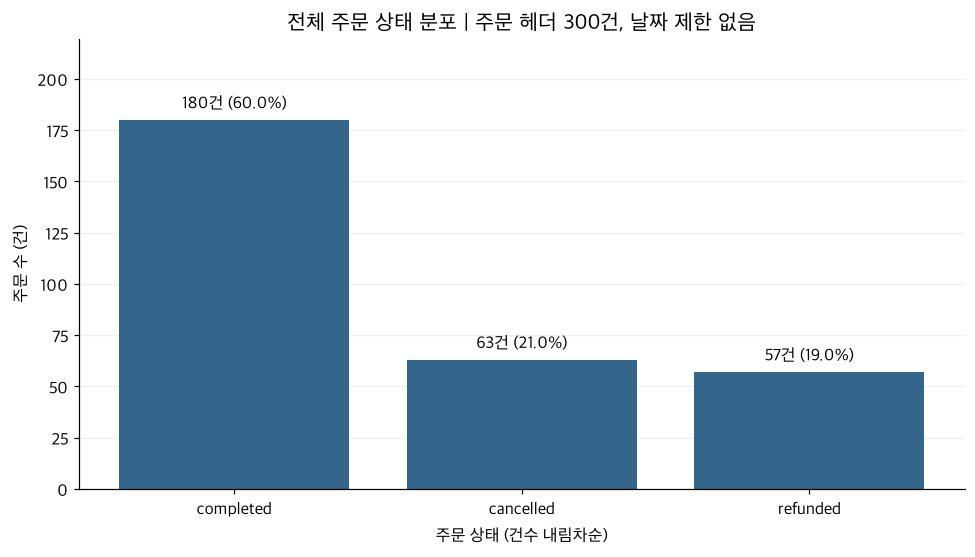

저장: images/graph06_status.png
실제 그래프 객체와 원본 집계표 검증: True


In [15]:
fig, checks = PLOTTERS["status"](viz_data)
chart_checks.extend(checks)
fig.savefig(IMAGE_DIR / FILENAMES["status"], bbox_inches="tight", facecolor="white")
display(fig)
plt.close(fig)
print("저장:", "images/" + FILENAMES["status"])
print("실제 그래프 객체와 원본 집계표 검증:", all(row["passed"] for row in checks))

### 원본 집계값

전체 **300건** 중 completed **180건(60%)**, cancelled **63건(21%)**, refunded **57건(19%)**이다. 상태별 막대 높이와 orders 헤더 총합을 검증했다.

### 결과 관찰

completed가 가장 크고 나머지 두 상태는 합계 120건이다. cancelled와 refunded는 6건 차이다. 금액 그래프에서 상세가 남은 completed 주문은 179건이지만 이 그래프의 completed는 헤더 기준 180건이다.

### 나의 해석과 판단

헤더 단위 상태 분포와 금액 산출 가능한 주문 범위를 구분하는 것이 중요하다고 판단했다. 상세가 없는 1건을 헤더 분포에서도 빼면 전체 상태 구성을 왜곡한다.

### 업무·분석적 의미

취소·환불 사유나 상태 전환 이력을 수집할 후속 질문을 정할 수 있다. 현재 결과는 주문 건수 구성 점검에 활용한다.

### 한계와 추가 확인 사항

현재 상태 스냅샷이어서 취소·환불 원인, 상태 전환율, 특정 기간의 취소율 추세는 알 수 없다. 40%를 금액 손실률로 바꾸지 않는다. 날짜 결측·미래 주문도 포함한다. **다음 질문:** 주문 발생·완료·취소·환불 시점과 사유를 확보하면 동일 기간 주문군의 상태 변화는 어떠한가?

## 9. 그래프와 숫자 교차 검증·정확성 점검

검증은 “동일한 표를 두 번 출력했다”에 그치지 않는다. 실제 `BarContainer`의 높이/너비, `Line2D`의 x·y 좌표, `hist`의 구간 경계·빈도·패치 높이, `PathCollection`의 모든 점 좌표를 읽어 원본 집계와 비교한다. 금액 총합은 주문 ID `isin` 방식으로도 독립 계산했다.

In [16]:
chart_validation = pd.DataFrame(chart_checks)
display(chart_validation)
assert chart_validation.passed.all()
print("집계 검증", len(viz_data["validation"]), "개 + 그래프 객체 검증", len(chart_validation), "개 통과")
assert len(list(IMAGE_DIR.glob("graph*.png"))) == 6
assert all(p.stat().st_size > 10000 for p in IMAGE_DIR.glob("graph*.png"))
# 그래프 생성 중 전처리 파일을 바꾸지 않았는지 마지막에 다시 확인한다.
assert input_hashes == {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                        for p in PROCESSED_DIR.glob("*_clean.csv")}
print("processed 원본 보존 / PNG 6개 존재·내용 크기 확인")

,check,actual,expected,passed
0,그래프1 막대 높이 = 집계표 전체,"141,340,000.00","141,340,000.00",True
1,그래프1 범주 순서,1.00,1.00,True
2,그래프1 금액 축 시작 0,0.00,0.00,True
3,그래프2 선 금액 = 월별 집계 전체,"138,528,000.00","138,528,000.00",True
4,그래프2 주문 수 = 월별 집계 전체,176.00,176.00,True
5,그래프2 실제 x 좌표 = 월 시작일,"286,557.00","286,557.00",True
6,그래프2 월 오름차순,1.00,1.00,True
7,그래프3 행1 bins=10 구간별 빈도,96.00,96.00,True
8,그래프3 행1 bins=10 실제 막대 높이,96.00,96.00,True
9,그래프3 행1 bins=10 구간 경계,"55,027,494.50","55,027,494.50",True


집계 검증 10 개 + 그래프 객체 검증 33 개 통과
processed 원본 보존 / PNG 6개 존재·내용 크기 확인


### 그래프 정확성 점검

| 항목 | 판단과 확인 결과 |
|---|---|
| 그래프 수치 | PASS — 대표 3개와 추가 3개 모두 실제 객체 값을 집계표와 비교 |
| 범위 | PASS — 금액은 completed, 가격 분포는 상품 전체, 상태는 orders 전체 |
| 축·단위 | PASS — 금액 원, 판매 수량 개, 주문 수 건. 월별 점 위 주석만 만원임을 명시 |
| 축 과장 | PASS — 막대 값 축·금액 선 y축 0 시작. 산점도 보조 x 로그 축은 제목에 명시 |
| 정렬 | PASS — 카테고리/고객/상태는 금액 또는 건수순, 월별은 날짜 오름차순 |
| 빈 기간·0 | PASS — 중간 달력 재색인, 전체 주문 부재는 NaN. 현재 중간 결측 월 없음. 관측 이후 9~10월을 0으로 보간하지 않음 |
| 관측 완전성 | CHECK — 첫/마지막 달·날짜 결측·상세 누락의 완전성은 확인 불가, 해석의 한계로 기록 |
| 개인정보 | PASS — 고객은 금액 순위 라벨만 공개. 이름·주소는 읽거나 출력하지 않음. 원본 고객 키는 병합·집계에만 사용하고 공개 출력에서 제외 |
| 범례·색상 | PASS — 주문 수 보조 패널 범례, 상품 미연결 라벨·빗금. 색상만으로 구분하지 않음 |
| 인과 해석 | PASS — 상관·월별 차이를 광고·가격의 원인 효과로 단정하지 않음 |

### 내가 발견한 시각화 위험 또는 개선점

| 문제 | 오해 가능성 | 수정 방법 | 수정 후 확인 |
|---|---|---|---|
| 상품 미연결의 inner join 제거 | 카테고리 합계가 조용히 감소 | left join·별도 범주·총합 보존 | 4,015,000원이 남고 141,340,000원과 일치 |
| 날짜 결측/미래를 월 그래프에 포함 | 미래 값과 오랜 빈 기간을 현재 추세로 오인 | 기준일 이하 유효 날짜만 사용·제외 금액 공개 | 138,528,000 + 1,903,000 + 909,000원 대조 |
| 관측 없는 달을 0으로 채움 | 데이터 누락을 실적 급락으로 오인 | NaN 유지·종료 뒤 월을 추가하지 않음 | 중간 결측 월 0개, 9~10월 미표시 |
| 극단 가격 하나가 축을 압축 | 나머지 상품 분포/관계가 안 보임 | 전체+범위 제한/로그 보조 패널 | 원본 96개 유지, 산점도 95점 유지 |
| 고객 raw ID·이름 표시 | 공개 저장소에서 개인정보 노출 | 순위 익명 라벨과 구매 횟수만 사용 | 공개 고객 집계에 개인 키 없음 |
| 금액·주문 수 이중 축 | 무관한 스케일로 동조를 과장 | 같은 시간축의 두 패널 사용 | 금액·건수 좌표 각각 검증 |

## 10. LLM 활용 검토와 공통 함수 재실행

**사용 도구·날짜:** Codex, 2026-10-28. 이 과제 요청을 바탕으로 그래프·코드·문장 초안을 함께 작성했다. 별도의 외부 LLM API 호출은 하지 않았다.

**Safe Context:** 테이블 스키마, 전처리 정책, 집계값만 분석 근거로 사용했다. 고객 이름·개인별 원본 행·인증정보를 시각화 검토에 사용하지 않았다.

**본 작업에 적용한 검토 지시:**
```text
Chapter 05 processed 데이터를 사용한다. 질문마다 그래프 선택 이유를 작성한다.
금액은 completed 상세 quantity × unit_price로 정의하고 먼저 원본 집계를 확인한다.
FK 미연결, 날짜 결측, 미래 날짜, 극단값을 숨기지 말고 범위 차이를 설명한다.
막대/선/histogram/scatter 실제 객체 값이 집계와 일치하는지 검증한다.
축·단위·정렬·결측 월·개인정보·인과 단정을 점검한다.
대표 그래프마다 원본 수치, 관찰, 판단, 업무 의미, 한계와 다음 질문을 쓴다.
```

| 초안·제안 | 실제 사용 여부 | 판단 이유·직접 검증 |
|---|---|---|
| 범주 막대·시간 선·가격 히스토그램 | 사용 | 질문과 대응. source total과 모든 객체 값을 검증 |
| 공식 모듈의 FK 오류 시 일괄 중단 방식 | 수정 후 사용 | 문제를 확인한 뒤 미연결 정책을 명시하고 금액을 별도 보존 |
| 전체 가격 범위의 히스토그램 하나 | 수정 후 사용 | 극단값 압축을 확인해 전체 유지+100만원 이하 보조+bins 비교 |
| 선형 가격 산점도 하나 | 수정 후 사용 | 전체 유지+동일 점 로그 축, 수량·좌표와 민감도 확인 |
| 상위 고객을 충성 고객으로 해석 | 보류 | 기간·최근성·다른 채널 부족. 금액·횟수 사실만 기술 |
| 월 증가를 광고·계절성의 효과로 설명 | 보류 | 관련 변수와 대조군 없음. 주문 수·주문당 금액 차이로 한정 |

LLM 문장의 자연스러움보다 실제 출력과 분석 가능 범위를 우선했다. 관측과 해석을 구분하고, 원인을 알 수 없는 경우 후속 질문으로 남겼다.

### 스크립트 재실행 방법

저장소 루트에서 다음을 실행하면 같은 공통 함수가 집계 CSV·검증표·그래프를 다시 생성한다.
```bash
.venv/bin/python chapter07/scripts/run_visualization.py
```
아래 셀도 같은 전체 생성 함수를 실행해 Notebook에서 만든 표와 실제 그래프 검증 결과를 다시 비교한다. 화면 출력이 충분한 집계·그래프는 별도 화면 캡처를 중복하지 않았다.

In [17]:
first_checks = chart_validation.copy()
rerun_result = viz.create_all_figures(viz_data, IMAGE_DIR, REPORT_DIR)
reread_checks = pd.read_csv(REPORT_DIR / "chart_validation.csv")
pd.testing.assert_frame_equal(first_checks, reread_checks, check_dtype=False)
for name in ["category", "monthly", "scatter", "customers", "status"]:
    saved = pd.read_csv(REPORT_DIR / f"{name}.csv")
    frame = viz_data[name]
    for column in frame.select_dtypes(include="number").columns:
        assert np.allclose(saved[column], frame[column], rtol=0, atol=1e-6, equal_nan=True)
print(rerun_result)
print("개별 실행과 공통 전체 재생성: 숫자·그래프 검증표 일치")

{'as_of': '2026-10-28', 'completed_amount': 141340000.0, 'aggregate_checks': 10, 'chart_checks': 33, 'all_passed': True, 'figures': ['graph01_category.png', 'graph02_monthly.png', 'graph03_price.png', 'graph04_scatter.png', 'graph05_customers.png', 'graph06_status.png']}
개별 실행과 공통 전체 재생성: 숫자·그래프 검증표 일치


## 11. Chapter 07 최종 판단

### 가장 중요한 그래프 1개와 이유

**대표 그래프 2인 월별 선그래프**를 선택했다. 금액이 변했다는 결과를 주문 수·주문당 금액으로 나누어 확인할 수 있고, 날짜 결측·미래 날짜·수집이 없는 기간을 처리하는 판단이 추세 자체를 바꿀 수 있기 때문이다.

### 그래프가 보여 준 사실

월별 관측 범위에서 2026년 8월은 **16,980,000원**으로 가장 높다. 7월 대비 금액 **89.38%**, 주문 수 **87.5%**, 주문당 금액 **약 1.00%** 증가가 함께 관측됐다. 카테고리에서는 패션 금액 비중이 **23.31%**, 상품 마스터에서는 96개 중 95개가 **197,000원 이하**다.

### 내가 해석한 내용

8월 금액 차이를 이해하는 첫 확인 지표는 관측된 주문 수라고 판단했다. 패션은 상품·주문 집중도를 먼저 살펴볼 후보이고, 극단 마스터 가격은 원천 검수 우선 대상이다. 이들은 후속 확인의 우선순위이며 원인에 대한 확정 결론이 아니다.

### 그래프만으로 말할 수 없는 것

광고·계절성·가격 변경의 인과 효과, 고객 충성도·만족도, 이익률, 관측 밖 실제 전체 매출은 알 수 없다. 데이터가 없는 달의 거래가 0인지, 미래 주문이 오류인지 예약 주문인지, 극단 가격이 잘못 입력된 것인지도 별도 확인이 필요하다.

### 시각화에서 가장 주의해야 한다고 느낀 점

그림의 모양보다 **어떤 분모와 범위를 보여 주는지**가 우선이다. 축을 예쁘게 꾸며도 미연결 거래를 빼거나 없는 달을 0으로 바꾸면 전달하는 사실이 달라진다. 원본 집계·범위 차이·제외 사유를 같이 제시하고 전체 그림을 유지한 보조 비교를 사용하는 것이 필요하다고 판단했다.

### 오해를 줄이기 위해 수정하거나 확인한 요소

- **축·단위:** 막대 금액 축 0, 원/건/개 표기, 선 주석 만원 별도 표시, 산점도 로그 축 명시.
- **정렬:** 범주는 값순·월은 실제 시간순으로 배열하고 그래프 객체에서 확인.
- **범위:** completed와 전체 orders/상품 마스터를 구분. 월별 제외 금액을 총액에 대조.
- **개인정보:** 고객 이름·원본 ID 대신 금액순 익명 순위만 표시.

### 다음 분석에서 확인할 질문

1. 상품 미연결 4,015,000원, 날짜 결측 1,903,000원, 미래 909,000원, 고객 미연결 376,000원과 상세 없는 completed 1건의 원천 사유는 무엇인가?
2. 월별 수집 완전성을 확인하고 날짜 범위를 통일한 뒤에도 7→8월 증가와 카테고리 순위가 유지되는가?
3. 8월 변화가 신규/반복 구매자·카테고리·고액 주문 중 어디에 집중되어 있는가?
4. 마스터 가격과 실제 거래단가의 차이, 상품 판매 기간·재고·노출을 반영하면 가격·수량 관계가 어떻게 달라지는가?

### 완료 체크

- ☑ 시각화 질문 6개와 선택 이유를 먼저 작성했다.
- ☑ 대표 그래프 3개와 추가 그래프 3개를 실행·저장했다.
- ☑ 그래프 전 원본 집계표와 completed 범위를 확인했다.
- ☑ 집계 총합과 실제 그래프 객체를 교차 검증했다.
- ☑ 축·단위·정렬·범례·개인정보를 점검했다.
- ☑ 데이터가 없는 기간과 파일 내 0을 구분했다.
- ☑ 각 그래프에 관찰·판단·업무 의미·한계·다음 질문을 기록했다.
- ☑ 관계를 원인으로 단정하지 않았고 LLM 초안을 검토했다.
- ☑ 공통 함수로 전체 그래프와 보고서를 재생성해 일치를 확인했다.

**제출:** GitHub 최종 렌더링 확인 후 상단의 최종 Notebook 파일 URL을 LMS에 제출한다. LMS 제출은 별도 절차다.